# Adım 4: Benzer Vaka Arşivi (CNN gömmeleri + FAISS)

Konseydeki literatür ajanının ilk kanıt kaynağı: **"Bu lezyona en çok benzeyen, tanısı bilinen geçmiş vakalar hangileri?"**

**Nasıl çalışır?**
1. Dondurulmuş son CNN (B0 v3 + B3 v3 topluluğu, TTA ile) her görüntü için bir **gömme vektörü** üretir. Bu vektör, modelin sınıflandırma katmanından hemen önceki katmanın (`gap`) çıktısıdır ve görüntünün "modelin gözündeki özetidir".
2. **Arşiv yalnızca eğitim kümesidir** (7.054 görüntü). Doğrulama ve test görüntüleri arşivde **aranır**, arşive eklenmez. Böylece bir vakanın kendisi ya da aynı lezyonun başka fotoğrafı asla "benzer vaka" olarak gelmez.
3. **FAISS** (Facebook AI Similarity Search) arşivdeki bütün vektörler arasında en benzer k tanesini milisaniyeler içinde bulur. Benzerlik ölçüsü kosinüs benzerliğidir (1 = aynı yön, 0 = ilgisiz).

**Bu defterde ölçülenler:**
- **Arşiv tek başına ne kadar iyi?** Benzer vakaların oylamasıyla tanı koyulsa başarı ne olur (k-en yakın komşu sınıflandırması)?
- **Arşiv CNN'e yeni bilgi katıyor mu?** CNN ile arşiv aynı şeyi söylediğinde ve farklı şey söylediğinde CNN ne kadar haklı? Uyumsuzluk, güvenden bağımsız bir "konsey toplansın" sinyali olabilir mi?
- **Veri kalitesi:** Eğitim kümesinde test görüntüsünün neredeyse kopyası olan, ama lezyon kimliği farklı görüntü var mı?

**Önceden yazılan kurallar:** k (komşu sayısı) ve oylama türü yalnızca doğrulama kümesinde seçilir: en yüksek dengeli doğruluk; 0,01 içinde ise küçük k. Test sonuçları raporlanır, hiçbir ayar teste göre değiştirilmez. CNN-arşiv uyumu analizi bir ayar değil, ön analizdir; konsey eşikleri Adım 8'de doğrulamada seçilecek.

**Çalışma zamanı:** GPU (T4 yeterli). Süre yaklaşık 30-45 dakika (10.015 görüntü × 2 model × 8 TTA yönü).

## 1. Ortam ve dondurulmuş son CNN

In [1]:
!pip -q install faiss-cpu
import os, json, glob, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
import faiss
from sklearn.metrics import balanced_accuracy_score, f1_score, classification_report

from google.colab import drive
drive.mount('/content/drive')
PROJE = '/content/drive/MyDrive/bitirme'

# ---- Ayarlar (sonuçlara bakmadan sabitlendi) ----
K_ADAYLARI = [5, 10, 20, 50]     # doğrulamada denenecek komşu sayıları
K_ARAMA = max(K_ADAYLARI)        # her sorgu için saklanacak komşu sayısı
K_GOSTER = 5                     # konsey raporunda gösterilecek benzer vaka sayısı
BATCH = 32
TOHUM = 42
ON = '04'
rng = np.random.default_rng(TOHUM)
warnings.filterwarnings('ignore', message='y_pred contains classes not in y_true')
os.makedirs(f'{PROJE}/rag', exist_ok=True)

with open(f'{PROJE}/results/03v2_son_cnn.json', encoding='utf-8') as f:
    SON_CNN = json.load(f)
SINIFLAR = SON_CNN['siniflar']
SINIF_ADI = {'akiec': 'Aktinik keratoz', 'bcc': 'Bazal hücreli karsinom', 'bkl': 'Benign keratoz',
             'df': 'Dermatofibrom', 'mel': 'Melanom', 'nv': 'Melanositik nevüs (ben)', 'vasc': 'Vasküler lezyon'}
ETIKET = [SINIF_ADI[s] for s in SINIFLAR]
MEL, NV = SINIFLAR.index('mel'), SINIFLAR.index('nv')
UYELER = [u['model'] for u in SON_CNN['uyeler']]
BILGI = {u['model']: u for u in SON_CNN['uyeler']}
TTA = SON_CNN['tta']
LOG_ONCEL = np.array(SON_CNN['log_oncel'])

MODELLER = {m: keras.models.load_model(f'{PROJE}/models/{m}.keras') for m in UYELER}
print('TensorFlow:', tf.__version__, '| FAISS:', faiss.__version__, '| GPU:', tf.config.list_physical_devices('GPU') or 'YOK')
print(f'Son CNN: {SON_CNN["aday"]} | üyeler: {UYELER} | TTA: {TTA} | T = {SON_CNN["T"]:.3f} | τ klinik = {SON_CNN["tau_klinik"]}')

Mounted at /content/drive


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adamw', because it has 232 variables whereas the saved optimizer has 236 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


TensorFlow: 2.21.0 | FAISS: 1.16.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Son CNN: Topluluk + TTA | üyeler: ['cnn_b0_v3', 'cnn_b3_v3'] | TTA: True | T = 1.178 | τ klinik = 0.8


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adamw', because it has 370 variables whereas the saved optimizer has 374 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [2]:
ZIP = f'{PROJE}/data/skin-cancer-mnist-ham10000.zip'
if not os.path.exists('/content/ham'):
    !unzip -q -n "{ZIP}" -d /content/ham
GORUNTU_KOKU = '/content/ham'

yollar = {}
for p in glob.glob(f'{GORUNTU_KOKU}/**/*.jpg', recursive=True):
    yollar.setdefault(os.path.splitext(os.path.basename(p))[0], p)

meta = pd.read_csv(f'{PROJE}/splits/ham10000_split.csv')
meta['path'] = meta['image_id'].map(yollar)
meta['y'] = meta['dx'].map({s: i for i, s in enumerate(SINIFLAR)})
assert meta['path'].notna().all()
assert meta.groupby('lesion_id')['split'].nunique().max() == 1

KUMELER = {k: meta[meta['split'] == k].reset_index(drop=True) for k in ['egitim', 'dogrulama', 'test']}
arsiv, dogrulama, test = KUMELER['egitim'], KUMELER['dogrulama'], KUMELER['test']
y_arsiv, y_dog, y_test = arsiv['y'].values, dogrulama['y'].values, test['y'].values
print({k: len(v) for k, v in KUMELER.items()})

{'egitim': 7054, 'dogrulama': 1464, 'test': 1497}


## 2. Gömme vektörleri
Her üye model için `gap` katmanının çıktısı alınır (B0: 1.280, B3: 1.536 boyut). Son CNN TTA kullandığı için gömmeler de 8 yönün **ortalamasıdır**; böylece aynı lezyonun döndürülmüş hali aynı vektörü verir.

İki modelin vektörleri ayrı ayrı **birim uzunluğa** getirilip birleştirilir (her model eşit ağırlıkta). Birleşik vektörün uzunluğu yine 1 olur; iç çarpım doğrudan kosinüs benzerliğidir.

**Tutarlılık kontrolü:** Sınıflandırma katmanı doğrusal olduğu için, ortalama gömmeyi bu katmandan geçirmek TTA logitlerinin ortalamasını vermelidir. Böylece hesaplanan gömmelerin Adım 3'teki son CNN ile aynı modelden geldiği doğrulanır (fark ≈0,05'in altında olmalı).

In [3]:
def onisle(goruntu, img, yontem):
    goruntu = tf.image.resize(goruntu, (img, img))
    if yontem == 'yuvarla_uint8':
        goruntu = tf.round(tf.clip_by_value(goruntu, 0, 255))
    return tf.cast(tf.cast(goruntu, tf.uint8), tf.float32)

def veri_hatti(df, m):
    img, yontem = BILGI[m]['img'], BILGI[m]['onisleme']
    def yukle(yol):
        return onisle(tf.io.decode_jpeg(tf.io.read_file(yol), channels=3), img, yontem)
    return (tf.data.Dataset.from_tensor_slices(df['path'].values)
            .map(yukle, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH).prefetch(tf.data.AUTOTUNE))

def gomme_hesapla(m, df):
    model = MODELLER[m]
    oznitelik = keras.Model(model.inputs, model.get_layer('gap').output)
    @tf.function(reduce_retracing=True)
    def adim(x):
        if not TTA:
            return tf.cast(oznitelik(x, training=False), tf.float32)
        gorunumler = []
        for aynala in (False, True):
            xx = tf.image.flip_left_right(x) if aynala else x
            for k in range(4):
                gorunumler.append(tf.cast(oznitelik(tf.image.rot90(xx, k), training=False), tf.float32))
        return tf.add_n(gorunumler) / float(len(gorunumler))
    return np.concatenate([adim(x).numpy() for x in veri_hatti(df, m)]).astype('float32')

def logit_katmani(m, g):
    W, b = MODELLER[m].get_layer('logit').get_weights()
    return g.astype('float64') @ W + b

HAM = {}
for k, df in KUMELER.items():
    for m in UYELER:
        t0 = time.time()
        HAM[(k, m)] = gomme_hesapla(m, df)
        print(f'{k:9s} {m}: {HAM[(k, m)].shape} | {(time.time() - t0) / 60:.1f} dk')

for k, dosya in [('dogrulama', 'son_cnn_dogrulama_logit.npy'), ('test', 'son_cnn_test_logit.npy')]:
    yeniden = np.mean([logit_katmani(m, HAM[(k, m)]) for m in UYELER], axis=0)
    fark = np.abs(yeniden - np.load(f'{PROJE}/models/{dosya}')).max()
    print(f'Tutarlılık ({k}): gömmelerden hesaplanan logitler ile Adım 3 logitleri arasındaki en büyük fark {fark:.4f} '
          f'-> {"TUTARLI" if fark < 0.05 else "DİKKAT: tutarsız, bana haber ver"}')

def birlestir(k):
    parcalar = [HAM[(k, m)] / np.linalg.norm(HAM[(k, m)], axis=1, keepdims=True) for m in UYELER]
    return (np.concatenate(parcalar, axis=1) / np.sqrt(len(UYELER))).astype('float32')

GOMME = {k: birlestir(k) for k in KUMELER}
for k, g in GOMME.items():
    np.save(f'{PROJE}/rag/gomme_{k}.npy', g)
print('Birleşik gömme boyutu:', GOMME['egitim'].shape[1], '| vektör uzunlukları ≈1:', np.allclose(np.linalg.norm(GOMME['test'], axis=1), 1, atol=1e-4))

egitim    cnn_b0_v3: (7054, 1280) | 2.7 dk
egitim    cnn_b3_v3: (7054, 1536) | 6.8 dk
dogrulama cnn_b0_v3: (1464, 1280) | 1.0 dk
dogrulama cnn_b3_v3: (1464, 1536) | 2.2 dk
test      cnn_b0_v3: (1497, 1280) | 1.0 dk
test      cnn_b3_v3: (1497, 1536) | 2.2 dk
Tutarlılık (dogrulama): gömmelerden hesaplanan logitler ile Adım 3 logitleri arasındaki en büyük fark 0.0000 -> TUTARLI
Tutarlılık (test): gömmelerden hesaplanan logitler ile Adım 3 logitleri arasındaki en büyük fark 0.0000 -> TUTARLI
Birleşik gömme boyutu: 2816 | vektör uzunlukları ≈1: True


## 3. FAISS arşivi ve arama
`IndexFlatIP`: Arşivdeki bütün vektörlerle tam (yaklaşıksız) iç çarpım araması. 7.054 vektör için bu, sorgu başına bir milisaniyeden kısa sürer; yaklaşık arama yöntemlerine gerek yoktur.

Kontroller:
- **Sızıntı yok:** Bir sorgunun komşuları arasında aynı lezyonun görüntüsü olmamalı (lezyon bazlı ayrım sayesinde).
- **Neredeyse kopya:** En benzer arşiv görüntüsüyle benzerliği 0,98'in üzerinde olan sorgular listelenir. HAM10000'de aynı lezyonun farklı kimlikle kaydedildiği bilinen durumlar vardır; bunlar varsa tezde not edilmelidir.

In [4]:
indeks = faiss.IndexFlatIP(GOMME['egitim'].shape[1])
indeks.add(GOMME['egitim'])
faiss.write_index(indeks, f'{PROJE}/rag/arsiv.faiss')
arsiv[['image_id', 'lesion_id', 'dx', 'dx_type', 'age', 'sex', 'localization']].to_csv(f'{PROJE}/rag/arsiv_meta.csv', index=False)
print('Arşivdeki vaka sayısı:', indeks.ntotal)

t0 = time.time()
BENZERLIK, KOMSU = {}, {}
for k in ['dogrulama', 'test']:
    BENZERLIK[k], KOMSU[k] = indeks.search(GOMME[k], K_ARAMA)
print(f'Arama süresi: {time.time() - t0:.2f} sn ({len(dogrulama) + len(test)} sorgu × {K_ARAMA} komşu)')

for k, df in [('dogrulama', dogrulama), ('test', test)]:
    ayni_lezyon = (arsiv['lesion_id'].to_numpy(dtype=str)[KOMSU[k]] == df['lesion_id'].to_numpy(dtype=str)[:, None]).sum()
    assert ayni_lezyon == 0, 'Sızıntı: aynı lezyon komşu olarak geldi!'
    ust = BENZERLIK[k][:, 0]
    yakin = np.where(ust > 0.98)[0]
    print(f'{k:9s}: sızıntı yok ✓ | en yakın komşu benzerliği ortanca {np.median(ust):.3f} | '
          f'0,98 üstü (neredeyse kopya) {len(yakin)} sorgu')
    if len(yakin):
        print(pd.DataFrame({'sorgu': df['image_id'].to_numpy(dtype=str)[yakin], 'sorgu_tani': df['dx'].to_numpy(dtype=str)[yakin],
                            'arsiv': arsiv['image_id'].to_numpy(dtype=str)[KOMSU[k][yakin, 0]],
                            'arsiv_tani': arsiv['dx'].to_numpy(dtype=str)[KOMSU[k][yakin, 0]],
                            'benzerlik': ust[yakin].round(4)}).head(15).to_string(index=False))

Arşivdeki vaka sayısı: 7054
Arama süresi: 1.17 sn (2961 sorgu × 50 komşu)
dogrulama: sızıntı yok ✓ | en yakın komşu benzerliği ortanca 0.819 | 0,98 üstü (neredeyse kopya) 0 sorgu
test     : sızıntı yok ✓ | en yakın komşu benzerliği ortanca 0.819 | 0,98 üstü (neredeyse kopya) 0 sorgu


## 4. Arşiv tek başına ne kadar iyi? (k-en yakın komşu)
Her sorgu için en benzer k arşiv vakası, benzerlikleriyle ağırlıklı oy verir:
- **ham oy:** Her komşu benzerliği kadar oy verir. Arşivde çok sayıda nevüs olduğu için oylar nevüse kayar.
- **dengeli oy:** Her sınıfın oyları, o sınıfın arşivdeki sıklığına bölünür (nadir sınıfların tek komşusu daha çok sayılır).

Oy dağılımı, **arşiv olasılığı** olarak saklanır; konsey ajanları ve bulanık mantık bunu kullanacak.

**Seçim (önceden yazıldı):** Doğrulamada en yüksek dengeli doğruluk; 0,01 içinde kalanlardan en küçük k.

In [5]:
ARSIV_SIKLIK = np.bincount(y_arsiv, minlength=len(SINIFLAR)) / len(y_arsiv)

def arsiv_olasilik(benzerlik, komsu, k, tip):
    w = np.clip(benzerlik[:, :k], 0, None).astype('float64')
    oy = np.zeros((len(w), len(SINIFLAR)))
    for c in range(len(SINIFLAR)):
        oy[:, c] = (w * (y_arsiv[komsu[:, :k]] == c)).sum(1)
    if tip == 'dengeli':
        oy = oy / ARSIV_SIKLIK
    oy = oy + 1e-6
    return oy / oy.sum(1, keepdims=True)

def duyarlilik(y, tahmin, sinif):
    m = y == sinif
    return float((tahmin[m] == sinif).mean()) if m.any() else np.nan

def olc(y, p, komsu=None, k=None):
    t = p.argmax(1)
    d = {'dengeli_dogruluk': balanced_accuracy_score(y, t), 'dogruluk': (t == y).mean(),
         'makro_f1': f1_score(y, t, average='macro'),
         'melanom_duy': duyarlilik(y, t, MEL), 'nevus_duy': duyarlilik(y, t, NV)}
    if komsu is not None:
        d['ayni_sinif_payi@k'] = (y_arsiv[komsu[:, :k]] == y[:, None]).mean()   # komşuların ne kadarı sorguyla aynı tanıda
    return d

satirlar = []
for k in K_ADAYLARI:
    for tip in ['ham', 'dengeli']:
        p = arsiv_olasilik(BENZERLIK['dogrulama'], KOMSU['dogrulama'], k, tip)
        satirlar.append({'k': k, 'oy': tip, **olc(y_dog, p, KOMSU['dogrulama'], k)})
k_tablo = pd.DataFrame(satirlar)
print('DOĞRULAMA: arşiv tek başına (k-en yakın komşu)\n')
print(k_tablo.round(3).to_string(index=False))

en_iyi = k_tablo['dengeli_dogruluk'].max()
secim = k_tablo[k_tablo['dengeli_dogruluk'] >= en_iyi - 0.01].sort_values(['k', 'dengeli_dogruluk'], ascending=[True, False]).iloc[0]
K_SECILEN, OY_SECILEN = int(secim['k']), secim['oy']
print(f'\nSEÇİLEN: k = {K_SECILEN}, oy = {OY_SECILEN} (doğrulama dengeli doğruluk {secim["dengeli_dogruluk"]:.3f})')

P_ARSIV = {k: arsiv_olasilik(BENZERLIK[k], KOMSU[k], K_SECILEN, OY_SECILEN) for k in ['dogrulama', 'test']}

# Karşılaştırma: aynı kümelerde son CNN
def softmax(z):
    z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)
LOGIT = {'dogrulama': np.load(f'{PROJE}/models/son_cnn_dogrulama_logit.npy'),
         'test': np.load(f'{PROJE}/models/son_cnn_test_logit.npy')}
P_CNN = {k: softmax(z / SON_CNN['T']) for k, z in LOGIT.items()}
KARAR_CNN = {k: (z - SON_CNN['tau_klinik'] * LOG_ONCEL).argmax(1) for k, z in LOGIT.items()}

karsilastirma = {}
for k, y in [('dogrulama', y_dog), ('test', y_test)]:
    karsilastirma[f'arsiv ({k})'] = olc(y, P_ARSIV[k], KOMSU[k], K_SECILEN)
    karsilastirma[f'CNN ayarsız ({k})'] = olc(y, P_CNN[k])
    t = KARAR_CNN[k]
    karsilastirma[f'CNN klinik ({k})'] = {'dengeli_dogruluk': balanced_accuracy_score(y, t), 'dogruluk': (t == y).mean(),
                                          'makro_f1': f1_score(y, t, average='macro'),
                                          'melanom_duy': duyarlilik(y, t, MEL), 'nevus_duy': duyarlilik(y, t, NV)}
print('\nArşiv ile son CNN (doğrulama ve test):')
print(pd.DataFrame(karsilastirma).T.round(3).to_string())

DOĞRULAMA: arşiv tek başına (k-en yakın komşu)

 k      oy  dengeli_dogruluk  dogruluk  makro_f1  melanom_duy  nevus_duy  ayni_sinif_payi@k
 5     ham             0.684     0.845     0.712        0.565      0.954              0.811
 5 dengeli             0.719     0.769     0.671        0.708      0.800              0.811
10     ham             0.699     0.848     0.736        0.542      0.955              0.807
10 dengeli             0.752     0.792     0.690        0.708      0.830              0.807
20     ham             0.691     0.851     0.732        0.512      0.962              0.797
20 dengeli             0.756     0.774     0.681        0.762      0.786              0.797
50     ham             0.660     0.850     0.706        0.500      0.970              0.782
50 dengeli             0.782     0.778     0.687        0.780      0.789              0.782

SEÇİLEN: k = 50, oy = dengeli (doğrulama dengeli doğruluk 0.782)

Arşiv ile son CNN (doğrulama ve test):
                  

In [6]:
rapor = classification_report(y_test, P_ARSIV['test'].argmax(1), labels=range(len(SINIFLAR)), target_names=ETIKET,
                              output_dict=True, zero_division=0)
print(f'TEST: arşivin sınıf bazında sonuçları (k = {K_SECILEN}, {OY_SECILEN} oy)')
print(pd.DataFrame({'ornek': [int(rapor[e]['support']) for e in ETIKET],
                    'duyarlilik': [rapor[e]['recall'] for e in ETIKET],
                    'kesinlik': [rapor[e]['precision'] for e in ETIKET],
                    f'ayni_sinif_payi@{K_GOSTER}': [(y_arsiv[KOMSU['test'][y_test == c, :K_GOSTER]] == c).mean() for c in range(len(SINIFLAR))]},
                   index=ETIKET).round(3).to_string())
print(f'\nayni_sinif_payi@{K_GOSTER}: konseyde gösterilecek {K_GOSTER} benzer vakanın ortalama kaçta kaçı sorguyla aynı tanıda.')

TEST: arşivin sınıf bazında sonuçları (k = 50, dengeli oy)
                         ornek  duyarlilik  kesinlik  ayni_sinif_payi@5
Aktinik keratoz             51       0.765     0.488              0.596
Bazal hücreli karsinom      77       0.844     0.619              0.732
Benign keratoz             157       0.656     0.665              0.567
Dermatofibrom               22       0.727     0.364              0.473
Melanom                    168       0.821     0.430              0.577
Melanositik nevüs (ben)   1000       0.748     0.973              0.897
Vasküler lezyon             22       0.864     0.826              0.709

ayni_sinif_payi@5: konseyde gösterilecek 5 benzer vakanın ortalama kaçta kaçı sorguyla aynı tanıda.


## 5. Arşiv CNN'e yeni bilgi katıyor mu? (ön analiz)
CNN'in ana kararı (klinik τ) ile arşivin kararı karşılaştırılır:
- **Uyumlu:** İkisi aynı tanıyı söylüyor. **Uyumsuz:** Farklı tanılar.
- CNN uyumlu vakalarda uyumsuz vakalardan belirgin biçimde daha doğruysa, uyumsuzluk bir **"konsey toplansın"** sinyalidir.
- **Kurtarılabilir hata:** CNN yanlışken arşivin doğru olduğu vakalar. Konseyin düzeltebileceği hataların üst sınırına dair bir fikir verir.

**Asıl soru:** Uyumsuzluk, CNN'in güveninin zaten söylediğinden fazlasını söylüyor mu? Bunun için iki yönlendirme kuralı **aynı oranda** vakayı uzmana gönderecek şekilde karşılaştırılır:
1. Yalnızca güvene göre (Adım 3'teki temel çizgi): En az emin olunan vakalar.
2. Güven + uyumsuzluk: Önce uyumsuz vakalar, kalan kontenjan en az emin olunanlarla doldurulur.

İkinci kural daha az melanom kaçırıyorsa veya daha yüksek doğruluk veriyorsa, arşiv konseye gerçekten yeni bilgi katıyor demektir.

In [7]:
def uyum_analizi(y, karar_cnn, p_cnn, p_arsiv):
    karar_arsiv = p_arsiv.argmax(1)
    uyum = karar_cnn == karar_arsiv
    dogru = karar_cnn == y
    return {'uyum_orani': uyum.mean(),
            'CNN_dogrulugu_uyumlu': dogru[uyum].mean(), 'CNN_dogrulugu_uyumsuz': dogru[~uyum].mean(),
            'CNN_yanlis_sayisi': int((~dogru).sum()),
            'kurtarilabilir_hata (CNN yanlış, arşiv doğru)': int((~dogru & (karar_arsiv == y)).sum()),
            'kaçan melanom (CNN)': int(((y == MEL) & (karar_cnn != MEL)).sum()),
            'bunlardan arşivin melanom dediği': int(((y == MEL) & (karar_cnn != MEL) & (karar_arsiv == MEL)).sum()),
            'yanlış alarm (nevüse melanom)': int(((y == NV) & (karar_cnn == MEL)).sum()),
            'bunlardan arşivin nevüs dediği': int(((y == NV) & (karar_cnn == MEL) & (karar_arsiv == NV)).sum())}

def yonlendir(y, karar_cnn, p_cnn, p_arsiv, kapsama, uyumsuzluk_kullan):
    guven = p_cnn[np.arange(len(y)), karar_cnn]
    oncelik = -guven                                   # büyük öncelik = önce uzmana
    if uyumsuzluk_kullan:
        oncelik = oncelik + 10.0 * (karar_cnn != p_arsiv.argmax(1))
    n_uzman = len(y) - int(round(kapsama * len(y)))
    uzman = np.zeros(len(y), bool); uzman[np.argsort(-oncelik)[:n_uzman]] = True
    karar_ver = ~uzman
    return {'dogruluk': (karar_cnn[karar_ver] == y[karar_ver]).mean(),
            'dengeli_dogruluk': balanced_accuracy_score(y[karar_ver], karar_cnn[karar_ver]),
            'kacirilan_melanom': int(((y == MEL) & karar_ver & (karar_cnn != MEL)).sum())}

UYUM, YONLENDIRME = {}, {}
for k, y in [('dogrulama', y_dog), ('test', y_test)]:
    UYUM[k] = uyum_analizi(y, KARAR_CNN[k], P_CNN[k], P_ARSIV[k])
    uyum_kapsamasi = round(float(UYUM[k]['uyum_orani']), 3)
    satirlar = []
    for kap in sorted({0.9, 0.8, 0.7, uyum_kapsamasi}, reverse=True):
        for ad, kullan in [('yalnız güven', False), ('güven + uyumsuzluk', True)]:
            satirlar.append({'kapsama': kap, 'kural': ad, **yonlendir(y, KARAR_CNN[k], P_CNN[k], P_ARSIV[k], kap, kullan)})
    YONLENDIRME[k] = pd.DataFrame(satirlar)

print('CNN (klinik karar) ile arşiv uyumu\n')
print(pd.DataFrame(UYUM).round(3).to_string())
for k in ['dogrulama', 'test']:
    print(f'\n--- Uzmana yönlendirme karşılaştırması ({k}) ---')
    print(YONLENDIRME[k].round(3).to_string(index=False))

CNN (klinik karar) ile arşiv uyumu

                                               dogrulama     test
uyum_orani                                         0.880    0.864
CNN_dogrulugu_uyumlu                               0.837    0.802
CNN_dogrulugu_uyumsuz                              0.511    0.358
CNN_yanlis_sayisi                                296.000  387.000
kurtarilabilir_hata (CNN yanlış, arşiv doğru)     61.000   91.000
kaçan melanom (CNN)                               29.000   22.000
bunlardan arşivin melanom dediği                   7.000    4.000
yanlış alarm (nevüse melanom)                    131.000  169.000
bunlardan arşivin nevüs dediği                    22.000   38.000

--- Uzmana yönlendirme karşılaştırması (dogrulama) ---
 kapsama              kural  dogruluk  dengeli_dogruluk  kacirilan_melanom
    0.90       yalnız güven     0.859             0.768                 22
    0.90 güven + uyumsuzluk     0.837             0.828                 21
    0.88       yalnız g

## 6. Örnekler: konseyin göreceği benzer vakalar
Her satırda solda sorgu (test görüntüsü), sağda arşivden gelen en benzer 5 vaka. Başlıklarda tanı, tanının nasıl doğrulandığı (patoloji, takip, uzman uzlaşısı, konfokal) ve benzerlik yazar. Konsey raporunda kanıt bu şekilde sunulacak.

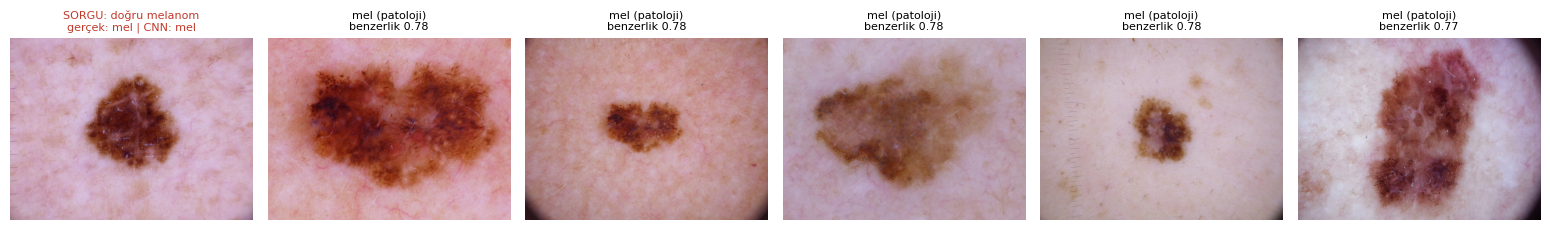

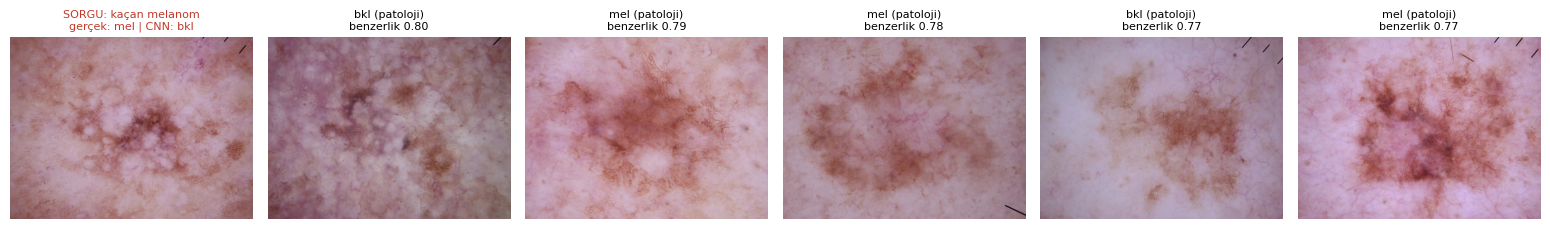

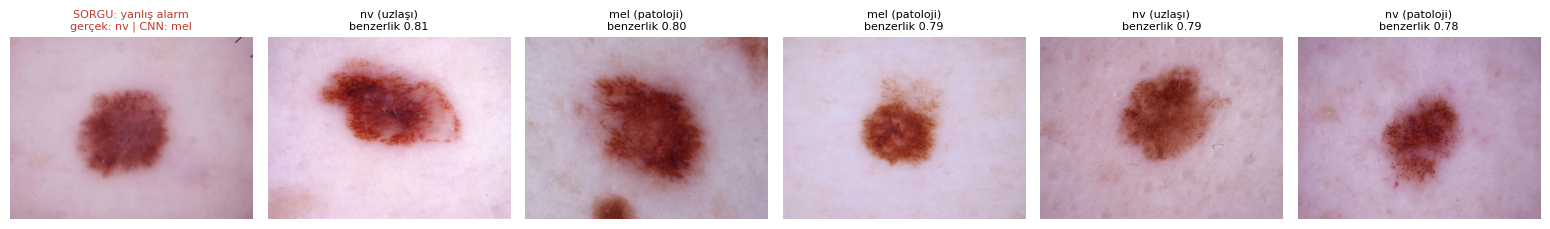

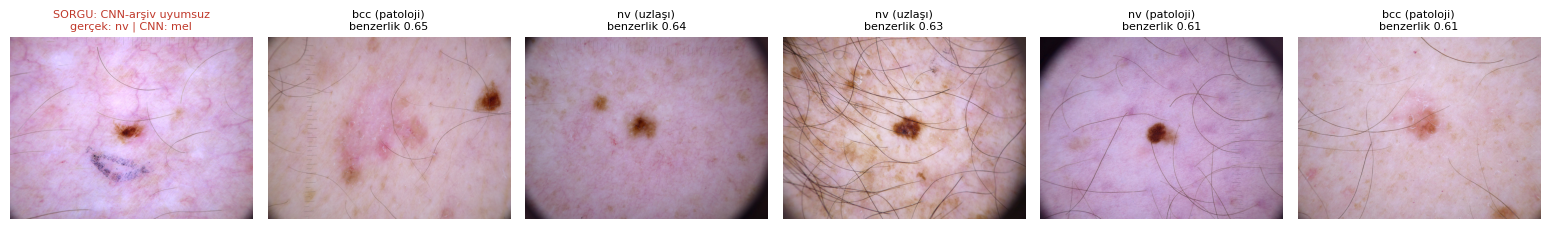

In [8]:
DX_TIPI = {'histo': 'patoloji', 'follow_up': 'takip', 'consensus': 'uzlaşı', 'confocal': 'konfokal'}
def goster(i, baslik):
    fig, eksen = plt.subplots(1, K_GOSTER + 1, figsize=(2.6 * (K_GOSTER + 1), 3.1))
    eksen[0].imshow(plt.imread(test.loc[i, 'path']))
    eksen[0].set_title(f'SORGU: {baslik}\ngerçek: {test.loc[i, "dx"]} | CNN: {SINIFLAR[KARAR_CNN["test"][i]]}', fontsize=8, color='#C0392B')
    for j in range(K_GOSTER):
        a = KOMSU['test'][i, j]
        eksen[j + 1].imshow(plt.imread(arsiv.loc[a, 'path']))
        eksen[j + 1].set_title(f'{arsiv.loc[a, "dx"]} ({DX_TIPI.get(arsiv.loc[a, "dx_type"], arsiv.loc[a, "dx_type"])})\n'
                               f'benzerlik {BENZERLIK["test"][i, j]:.2f}', fontsize=8)
    for ax in eksen: ax.axis('off')
    plt.tight_layout(); return fig

karar_arsiv_test = P_ARSIV['test'].argmax(1)
gruplar = {'doğru melanom': np.where((y_test == MEL) & (KARAR_CNN['test'] == MEL))[0],
           'kaçan melanom': np.where((y_test == MEL) & (KARAR_CNN['test'] != MEL))[0],
           'yanlış alarm': np.where((y_test == NV) & (KARAR_CNN['test'] == MEL))[0],
           'CNN-arşiv uyumsuz': np.where(KARAR_CNN['test'] != karar_arsiv_test)[0]}
for r, (ad, ix) in enumerate(gruplar.items()):
    if len(ix):
        fig = goster(int(rng.choice(ix)), ad)
        fig.savefig(f'{PROJE}/results/{ON}_benzer_vaka_ornek_{r + 1}.png', dpi=110); plt.show()

## 7. Gömme uzayının haritası (t-SNE)
Arşivden rastgele 3.000 görüntünün gömmeleri iki boyuta indirilir. Aynı tanıdaki vakalar bir arada kümeleniyorsa, model anlamlı bir benzerlik ölçüsü öğrenmiştir. Melanom ile nevüs kümelerinin iç içe geçtiği bölge, konseyin en çok çalışacağı "gri bölge"dir.

t-SNE süresi: 0.5 dk


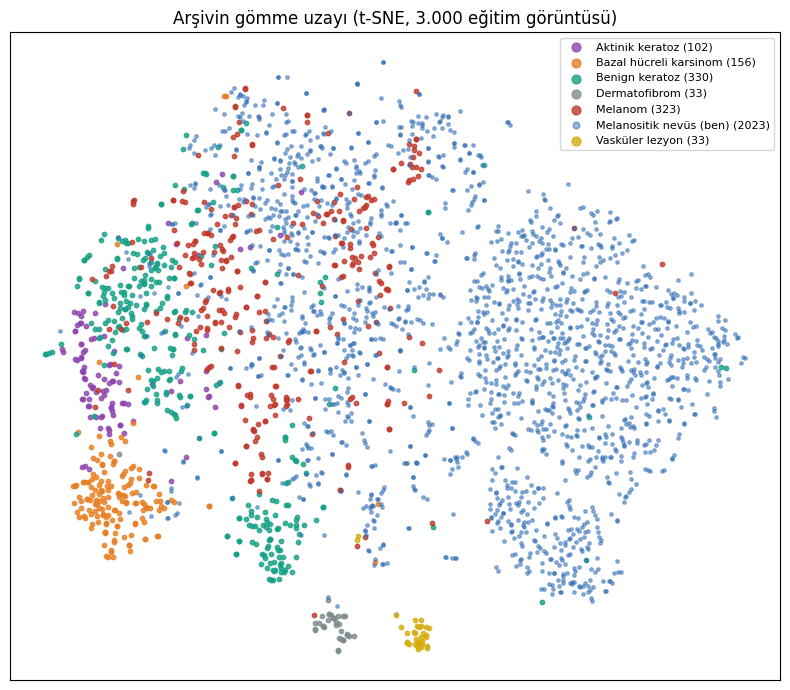

In [9]:
from sklearn.manifold import TSNE
n = min(3000, len(arsiv))
ix = rng.choice(len(arsiv), size=n, replace=False)
t0 = time.time()
xy = TSNE(n_components=2, perplexity=30, init='pca', random_state=TOHUM).fit_transform(GOMME['egitim'][ix])
print(f't-SNE süresi: {(time.time() - t0) / 60:.1f} dk')
renk = ['#8E44AD', '#E67E22', '#16A085', '#7F8C8D', '#C0392B', '#2F6DB5', '#D4AC0D']
fig, ax = plt.subplots(figsize=(8, 7))
for c in range(len(SINIFLAR)):
    m = y_arsiv[ix] == c
    ax.scatter(xy[m, 0], xy[m, 1], s=6 if c == NV else 10, alpha=0.5 if c == NV else 0.8, color=renk[c], label=f'{ETIKET[c]} ({m.sum()})')
ax.legend(markerscale=2, fontsize=8); ax.set_xticks([]); ax.set_yticks([])
ax.set_title('Arşivin gömme uzayı (t-SNE, 3.000 eğitim görüntüsü)')
plt.tight_layout(); plt.savefig(f'{PROJE}/results/{ON}_gomme_tsne.png', dpi=150); plt.show()

## 8. Kaydet
- `rag/arsiv.faiss`, `rag/arsiv_meta.csv`: arşivin kendisi (sonraki adımlar ve web arayüzü bunu yükler).
- `rag/gomme_*.npy`: gömmeler. `rag/komsular_*.npz`: doğrulama ve test sorgularının 50 komşusu ve benzerlikleri.
- `rag/arsiv_olasilik_*.npy`: arşiv olasılıkları (bulanık mantık ve ajanlar için).
- `rag/04_arsiv_ayarlari.json`: seçilen k, oy türü ve gömmenin nasıl üretildiği.

In [10]:
for k in ['dogrulama', 'test']:
    np.savez(f'{PROJE}/rag/komsular_{k}.npz', komsu=KOMSU[k], benzerlik=BENZERLIK[k])
    np.save(f'{PROJE}/rag/arsiv_olasilik_{k}.npy', P_ARSIV[k])

ayarlar = {'son_cnn': SON_CNN['aday'], 'uyeler': UYELER, 'tta': TTA, 'katman': 'gap',
           'gomme_boyutu': int(GOMME['egitim'].shape[1]), 'birlestirme': 'üye başına L2 normalize, birleştir, / sqrt(üye sayısı)',
           'indeks': 'IndexFlatIP (kosinüs)', 'arsiv': 'egitim', 'arsiv_boyutu': int(indeks.ntotal),
           'k': K_SECILEN, 'oy': OY_SECILEN, 'k_goster': K_GOSTER, 'arsiv_siklik': ARSIV_SIKLIK.tolist(),
           'secim_kurali': 'en yüksek doğrulama dengeli doğruluğu; 0,01 içinde ise en küçük k'}
with open(f'{PROJE}/rag/04_arsiv_ayarlari.json', 'w', encoding='utf-8') as f:
    json.dump(ayarlar, f, ensure_ascii=False, indent=2)
with open(f'{PROJE}/results/{ON}_arsiv_sonuclari.json', 'w', encoding='utf-8') as f:
    json.dump({'ayarlar': ayarlar, 'k_secim_tablosu': k_tablo.to_dict(orient='records'),
               'karsilastirma': {a: {b: float(c) for b, c in d.items()} for a, d in karsilastirma.items()},
               'uyum': {k: {a: float(b) for a, b in d.items()} for k, d in UYUM.items()},
               'yonlendirme': {k: v.to_dict(orient='records') for k, v in YONLENDIRME.items()},
               'en_yakin_benzerlik_ortanca': {k: float(np.median(BENZERLIK[k][:, 0])) for k in BENZERLIK}},
              f, ensure_ascii=False, indent=2, default=float)

print('Kaydedildi:')
for p in ['rag/arsiv.faiss', 'rag/arsiv_meta.csv', 'rag/gomme_egitim.npy', 'rag/gomme_dogrulama.npy', 'rag/gomme_test.npy',
          'rag/komsular_dogrulama.npz', 'rag/komsular_test.npz', 'rag/arsiv_olasilik_dogrulama.npy', 'rag/arsiv_olasilik_test.npy',
          'rag/04_arsiv_ayarlari.json', f'results/{ON}_arsiv_sonuclari.json', f'results/{ON}_gomme_tsne.png']:
    print(' ', p, '✓' if os.path.exists(f'{PROJE}/{p}') else 'YOK!')

Kaydedildi:
  rag/arsiv.faiss ✓
  rag/arsiv_meta.csv ✓
  rag/gomme_egitim.npy ✓
  rag/gomme_dogrulama.npy ✓
  rag/gomme_test.npy ✓
  rag/komsular_dogrulama.npz ✓
  rag/komsular_test.npz ✓
  rag/arsiv_olasilik_dogrulama.npy ✓
  rag/arsiv_olasilik_test.npy ✓
  rag/04_arsiv_ayarlari.json ✓
  results/04_arsiv_sonuclari.json ✓
  results/04_gomme_tsne.png ✓
